# Migration relative to resident population: rate test



**Statistics** follow the manuscript's rules: comparisons with IMD change and the modal gentrification label use the Section 4.1 statistics (Spearman's ρ; χ², Cramér's V). Comparisons with subtype presence flags are descriptive, in percentage points from the London-wide share (Section 4.3).

**Run** from `scripts/` or the repository root, after running steps 01-07. Inputs from `data/` (gitignored):

| File | Contents | Required |
|---|---|---|
| `ks101ew_lsoa_2011.csv` | 2011 Census usual residents (KS101EW), LSOA | yes |
| `nomis_2021_ts001.xlsx` (or `ts001_msoa_2021.csv`) | 2021 Census usual residents (TS001), MSOA 2021 | yes |
| `MSOA_2011_to_2021_lookup_for_identification.csv` | ONS MSOA 2011–2021 change lookup, as used in step 01 | recommended (exact 2021 mapping) |
| `yee_LSOA_labels_forMapping.csv` | Yee and Dennett (2022) LSOA labels | optional (else the strict label is rebuilt from `outputs/`) |

The notebook expresses each zone's retained migration **per 1,000 usual residents** and asks two questions:

1. **Scale.** How large are hierarchy-crossing flows relative to the people living in each zone, overall, by mechanism profile, and for Camden 026 and Croydon 044?
2. **Magnitude test.** Section 4.1 suggests that weak correspondence might arise because cascade dominance "described the direction of a zone's hierarchy-crossing migration, not the volume of that migration relative to the resident population". Is correspondence stronger where the net cascade balance is large relative to the population?

**Two rates** (per 1,000 usual residents, P), with C = IW + OP (cascade direction), E = OW + IP (escalator direction) and T = Total_Migration:

| Rate | Definition | Identity with the classification measures |
|---|---|---|
| Hierarchy-crossing rate | (C + E) / P | Cross_Decile_Share × T / P |
| Net cascade rate | (C − E) / P | (2 × Cascade_Dominance − 1) × Cross_Decile_Share × T / P |

The rates are the two classification measures multiplied by one extra factor, T / P (retained moves per resident).

In [ ]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, spearmanr
from IPython.display import display

warnings.filterwarnings("ignore", message="Workbook contains no default style")
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)  # many derived columns

ROOT = Path.cwd()
if not (ROOT / "outputs").exists() and (ROOT.parent / "outputs").exists():
    ROOT = ROOT.parent
OUT, DATA, SCRIPTS = ROOT / "outputs", ROOT / "data", ROOT / "scripts"
if str(SCRIPTS) not in sys.path:
    sys.path.insert(0, str(SCRIPTS))

STAMP = "20261112"

# analysis outputs (step 01-07)
FLOWS = OUT / "msoa_cascade_national_frame_20260625.csv"      # Frame A and Frame C flows
EDA4 = OUT / "eda4_results_for_phase3_20260626.csv"           # Dom, CDS, regimes, Frames A-C
EDA12 = OUT / "eda12_yee_leaf_corroboration_20260705.csv"     # profiles, subtype presence
LSOA_LOOKUP = OUT / "lsoa11_to_msoa11.csv"
PUB_CROSSTAB = OUT / "manuscript_aggregate_crosstab_20261021.csv"  # Table 4 counts (check)
PUB_TABLE3 = OUT / "manuscript_table3_20261021.csv"                # Table 3 values (check)
REMAP_AUDIT = OUT / "geo_harmonisation_remap_audit.csv"

# raw inputs (data/, gitignored)
POP11 = DATA / "ks101ew_lsoa_2011.csv"
POP21_XLSX = DATA / "nomis_2021_ts001.xlsx"
POP21_CSV = DATA / "ts001_msoa_2021.csv"
MSOA_LOOKUP = DATA / "MSOA_2011_to_2021_lookup_for_identification.csv"
YEE = DATA / "yee_LSOA_labels_forMapping.csv"

# outputs written by this notebook
OUT_ZONES = OUT / f"diag_population_rates_zones_{STAMP}.csv"
OUT_RESULTS = OUT / f"diag_population_rates_results_{STAMP}.csv"
OUT_FIG_CASES = OUT / f"diag_population_rates_cases_{STAMP}.png"
OUT_FIG_THIRDS = OUT / f"diag_population_rates_thirds_{STAMP}.png"

FRAMES = ["A", "B", "C"]
YEARS = [("11", "2011"), ("21", "2021")]
PER = 1000                      # rates per 1,000 usual residents
EXT_DECILE = 6                  # rest of England node, national Decile 6 (Frame C)
PROFILES = [("inflow-driven", "Inflow-driven, frame-robust"),
            ("frame-sensitive", "Frame-sensitive inflow"),
            ("outflow-internal", "Outflow-internal-majority"),
            ("outflow-external", "Outflow-external-majority")]
CASES = [("E02000191", "Camden 026"), ("E02000237", "Croydon 044")]

assert POP11 is not None, "2011 KS101EW file not found in data/"
print("Repository root:", ROOT)
for p in [POP11, POP21_XLSX, POP21_CSV, MSOA_LOOKUP, YEE]:
    print(f"  {'found  ' if p.exists() else 'missing'}  data/{p.name}")

Repository root: /Users/xing/Desktop/publication/master-dissertation/dissertation-manuscript-replication
  found    data/ks101ew_lsoa_2011_allengland.csv
  found    data/nomis_2021_ts001.xlsx
  missing  data/ts001_msoa_2021.csv
  found    data/MSOA_2011_to_2021_lookup_for_identification.csv
  found    data/yee_LSOA_labels_forMapping.csv


## 0. Analysis files and the modal gentrification label

The modal label uses the manuscript's strict plurality rule (35 zones). With `data/yee_LSOA_labels_forMapping.csv` present it is derived exactly as in `07_table3_aggregate_correspondence.py`. Without it, it is rebuilt from the EDA 12 file by switching off the six zones listed in `outputs/manuscript_aggregate_correspondence_20261021.md` as changed by the strict rule. Either way, it must reproduce the published Table 4 counts in all six frame-window comparisons.

In [2]:
flows = pd.read_csv(FLOWS)
e4 = pd.read_csv(EDA4)
y12 = pd.read_csv(EDA12)
for c in ["has_gen", "any_SupGen", "any_MainGen", "any_MargGen", "gen_modal"]:
    y12[c] = y12[c].astype(str).str.lower().eq("true")

# Zones whose modal status changed when the strict plurality rule replaced the
# EDA 12 rule (outputs/manuscript_aggregate_correspondence_20261021.md, section 3).
STRICT_RULE_CHANGES = ["E02000061", "E02000487", "E02000570",
                       "E02000595", "E02000888", "E02000960"]


def strict_modal_label():
    if YEE.exists():
        yee = pd.read_csv(YEE).rename(columns={"LSOA_Code": "lsoa11cd"})
        lk = pd.read_csv(LSOA_LOOKUP)[["lsoa11cd", "msoa11cd"]].drop_duplicates().dropna()
        yg = yee.merge(lk, on="lsoa11cd", how="inner")
        counts = pd.crosstab(yg["msoa11cd"], yg["Class_2_status"])
        gen = counts["GEN"] > counts.drop(columns="GEN").max(axis=1)
        return gen.reindex(y12["msoa11cd"]).fillna(False).astype(bool), "Yee LSOA labels (as in step 07)"
    gen = y12.set_index("msoa11cd")["gen_modal"].copy()
    gen.loc[STRICT_RULE_CHANGES] = ~gen.loc[STRICT_RULE_CHANGES]
    return gen, "EDA 12 label with the six strict-rule changes"


gen_modal, label_source = strict_modal_label()
assert gen_modal.sum() == 35, gen_modal.sum()

keep_e4 = ["msoa11cd", "Ring", "IMD_Pctile_Change"] + [
    f"{m}_{fr}_{yr}" for m in ("Dom", "CDS", "Typ") for fr in FRAMES for yr, _ in YEARS]
keep_y12 = ["msoa11cd", "msoa_name", "leaf_11", "leaf_21", "Ext_Arm_Share_11",
            "Ext_Arm_Share_21", "has_gen", "any_SupGen", "any_MainGen", "any_MargGen"]
d = (flows.drop(columns=["IMD_Pctile_Change"])
     .merge(e4[keep_e4], on="msoa11cd")
     .merge(y12[keep_y12], on="msoa11cd"))
d["gen_modal"] = gen_modal.reindex(d["msoa11cd"]).values
assert len(d) == 982

# Check: the label reproduces the published Table 4 counts
pub = pd.read_csv(PUB_CROSSTAB)
for _, r in pub.iterrows():
    yr = str(r.window)[2:]
    cl = d[f"Typ_{r.frame}_{yr}"].eq("Cascade-led")
    got = [(cl & d.gen_modal).sum(), (cl & ~d.gen_modal).sum(),
           (~cl & d.gen_modal).sum(), (~cl & ~d.gen_modal).sum()]
    assert got == [r.cascade_gen, r.cascade_not_gen, r.other_gen, r.other_not_gen], (r.frame, r.window)
print(f"Modal label: {int(d.gen_modal.sum())} zones, from {label_source}.")
print("Reproduces the published Table 4 counts in all six frame-window comparisons.")

Modal label: 35 zones, from Yee LSOA labels (as in step 07).
Reproduces the published Table 4 counts in all six frame-window comparisons.


## 1. Population denominators

Each window uses its own census: 2011 Census usual residents for the 2011 window and 2021 Census usual residents for the 2021 window. Both are counted on census day, at the end of the one-year migration window, which is the usual denominator for census migration rates.

**2011.** KS101EW LSOA counts are summed to the 982 zones through `outputs/lsoa11_to_msoa11.csv`, with the Camden merge (E02000190 into E02000189) applied as in step 01.

**2021.** TS001 MSOA counts are mapped to the 982 zones with the same harmonisation as step 01. Unchanged MSOAs keep their code, split MSOAs are summed back to their 2011 parent, and the Camden merge forms one zone. The mapping comes from the first source available:

1. `data/MSOA_2011_to_2021_lookup_for_identification.csv` with `geo_harmonise.build_harmonisation()` (exact, as in step 01);
2. `outputs/geo_harmonisation_remap_audit.csv` (exact);
3. otherwise a fallback: 2021 codes matching a zone code map to it, and new 2021 codes map to the borough's split parent. Where a borough has two split parents, their children's combined 2021 population is shared in proportion to the parents' 2011 populations. Those zones are flagged and listed below.

In [3]:
# ---- geography: 2021 MSOA -> zone, and the 2011 merge collapse ----
def read_ts001():
    if POP21_CSV.exists():
        ts = pd.read_csv(POP21_CSV)
        code = next(c for c in ts.columns if ts[c].astype(str).str.match(r"^[EW]02\d{6}$").mean() > 0.9)
        val = next(c for c in ts.columns if c.lower() in ("observation", "obs_value")
                   or "usual residents" in c.lower() or "total" in c.lower())
        ts = ts[[code, val]].set_axis(["msoa21cd", "pop"], axis=1)
        ts["name"] = ""
    else:
        x = pd.read_excel(POP21_XLSX, header=None)   # Nomis sheet: "E02002483 : Hartlepool 001" | count | %
        parts = x[0].astype(str).str.extract(r"^([EW]02\d{6})\s*:\s*(.*)$")
        ts = pd.DataFrame({"msoa21cd": parts[0], "name": parts[1], "pop": x[1]}).dropna(subset=["msoa21cd"])
    ts["pop"] = pd.to_numeric(ts["pop"], errors="coerce")
    assert ts["pop"].notna().all()
    return ts.reset_index(drop=True)


ts001 = read_ts001()
zones = set(d["msoa11cd"])
pop11_lsoa_lookup = pd.read_csv(LSOA_LOOKUP)[["lsoa11cd", "msoa11cd"]].drop_duplicates()

approx_2021 = []          # zones whose 2021 population is apportioned (fallback only)
if MSOA_LOOKUP.exists():
    from geo_harmonise import build_harmonisation
    h = build_harmonisation(pd.read_csv(MSOA_LOOKUP), set(pop11_lsoa_lookup["msoa11cd"]))
    remap_2021, collapse_2011 = h.remap_2021, h.collapse_2011
    geo_source = "ONS MSOA 2011-2021 lookup via geo_harmonise.build_harmonisation (exact)"
elif REMAP_AUDIT.exists():
    rm = pd.read_csv(REMAP_AUDIT)
    remap_2021 = dict(zip(rm["msoa21cd"], rm["canonical_msoa11"]))
    collapse_2011 = {"E02000190": "E02000189"}
    geo_source = "outputs/geo_harmonisation_remap_audit.csv (exact)"
else:
    remap_2021 = None
    collapse_2011 = {"E02000190": "E02000189"}     # Camden merge (step 03 output)
    geo_source = "FALLBACK: code match plus borough-level assignment of split children"
print("2021 geography:", geo_source)

2021 geography: ONS MSOA 2011-2021 lookup via geo_harmonise.build_harmonisation (exact)


In [4]:
# ---- 2011: KS101EW LSOA -> zone ----
ks = pd.read_csv(POP11)
code_col = next(c for c in ks.columns if ks[c].astype(str).str.match(r"^[EW]01\d{6}$").mean() > 0.9)
val_col = next(c for c in ks.columns if "all usual residents" in c.lower())
ks = ks[[code_col, val_col]].set_axis(["lsoa11cd", "pop"], axis=1)
ks["pop"] = pd.to_numeric(ks["pop"], errors="coerce")

l11 = pop11_lsoa_lookup.merge(ks, on="lsoa11cd", how="left")
assert l11["pop"].notna().all(), "London LSOAs missing from KS101EW"
l11["zone"] = l11["msoa11cd"].replace(collapse_2011)
pop11 = l11.groupby("zone")["pop"].sum()
assert set(pop11.index) == zones
print(f"2011: {len(l11):,} London LSOAs -> {pop11.size} zones, {pop11.sum():,.0f} usual residents")

# ---- 2021: TS001 MSOA 2021 -> zone ----
ts001["lad"] = ts001["name"].str.replace(r"\s+\d{3}$", "", regex=True)
if remap_2021 is not None:
    lon21 = ts001[ts001["msoa21cd"].isin(remap_2021.keys())].copy()
    lon21["zone"] = lon21["msoa21cd"].map(remap_2021)
    pop21 = lon21.groupby("zone")["pop"].sum()
else:
    boroughs = set(d["ladnm"])
    lon21 = ts001[ts001["lad"].isin(boroughs)].copy()
    lon21["zone"] = lon21["msoa21cd"].where(lon21["msoa21cd"].isin(zones))
    gone = d.loc[~d["msoa11cd"].isin(lon21["msoa21cd"]), ["msoa11cd", "ladnm"]]
    pop21 = lon21.dropna(subset=["zone"]).groupby("zone")["pop"].sum()
    for lad, g in gone.groupby("ladnm"):
        children = lon21[(lon21["lad"] == lad) & lon21["zone"].isna()]
        assert len(children) > 0, lad
        parents = g["msoa11cd"].tolist()
        w = pop11.reindex(parents) / pop11.reindex(parents).sum()
        for p in parents:
            pop21.loc[p] = children["pop"].sum() * w[p]
        if len(parents) > 1:
            approx_2021 += parents
pop21 = pop21.reindex(sorted(zones))
assert pop21.notna().all() and (pop21 > 0).all()
print(f"2021: {len(lon21):,} London MSOAs -> {pop21.size} zones, {pop21.sum():,.0f} usual residents")
if approx_2021:
    print(f"       {len(approx_2021)} zones with an apportioned 2021 population (fallback): "
          + ", ".join(approx_2021))

d["pop_2011"] = pop11.reindex(d["msoa11cd"]).values
d["pop_2021"] = pop21.reindex(d["msoa11cd"]).values
d["pop21_approx"] = d["msoa11cd"].isin(approx_2021)
if approx_2021:
    cl_any = d.loc[d.pop21_approx, [f"Typ_{fr}_21" for fr in FRAMES]].eq("Cascade-led").any(axis=1)
    print(f"       Apportioned zones that are Cascade-led in 2021 under any frame: {int(cl_any.sum())}"
          + (" (sections 4-6 do not depend on the fallback)" if cl_any.sum() == 0 else ""))

2011: 4,835 London LSOAs -> 982 zones, 8,173,941 usual residents
2021: 1,002 London MSOAs -> 982 zones, 8,799,742 usual residents


In [5]:
popsum = pd.DataFrame({
    "Zones": [982, 982],
    "Total residents": [d.pop_2011.sum(), d.pop_2021.sum()],
    "Median": [d.pop_2011.median(), d.pop_2021.median()],
    "P5": [d.pop_2011.quantile(.05), d.pop_2021.quantile(.05)],
    "P95": [d.pop_2011.quantile(.95), d.pop_2021.quantile(.95)],
    "Min": [d.pop_2011.min(), d.pop_2021.min()],
    "Max": [d.pop_2011.max(), d.pop_2021.max()],
}, index=["2011 Census (KS101EW)", "2021 Census (TS001)"]).round(0).astype(int)
display(popsum)
g = d.pop_2021 / d.pop_2011
print(f"Population change 2011-2021 by zone: median {100*(g.median()-1):+.1f}%, "
      f"P5 {100*(g.quantile(.05)-1):+.1f}%, P95 {100*(g.quantile(.95)-1):+.1f}%")
if approx_2021:
    display(d.loc[d.pop21_approx, ["msoa11cd", "msoa_name", "pop_2011", "pop_2021"]]
            .assign(pop_2021=lambda t: t.pop_2021.round(0)).set_index("msoa11cd"))

,Zones,Total residents,Median,P5,P95,Min,Max
2011 Census (KS101EW),982,8173941,8158,6314,10813,5184,14719
2021 Census (TS001),982,8799742,8615,6378,12729,5337,23952


Population change 2011-2021 by zone: median +5.4%, P5 -6.9%, P95 +26.4%


## 2. Rates per 1,000 residents

For each frame and window: retained moves (T), hierarchy-crossing moves (C + E) and the net cascade balance (C − E), each divided by the zone's population. They are computed from the classification measures through the identity above, then **checked against the raw flows** for Frames A and C. Frame B uses the London-internal flows of Frame A ranked on the national ladder, so it has Frame A's retained moves but its own hierarchy-crossing and net values.

For Frame C, the four elementary flows are also split into moves within London and moves to or from the rest of England, as in Figure 4. The rest of England sits at national Decile 6, so its exchanges with a zone are cascade-direction departures where the zone's national decile is above 6, and cascade-direction arrivals where it is below 6.

In [6]:
for yr, Y in YEARS:
    P = d[f"pop_{Y}"]
    total = {"A": d[f"Total_Migration_{yr}"], "B": d[f"Total_Migration_{yr}"],
             "C": d[f"Total_Migration_nat_{yr}"]}
    for fr in FRAMES:
        X = (d[f"CDS_{fr}_{yr}"] * total[fr]).round()                 # C + E
        N = ((2 * d[f"Dom_{fr}_{yr}"] - 1) * X).round()               # C - E
        d[f"xdec_{fr}_{Y}"], d[f"net_{fr}_{Y}"] = X, N
        d[f"retained_rate_{fr}_{Y}"] = PER * total[fr] / P
        d[f"xdec_rate_{fr}_{Y}"] = PER * X / P
        d[f"net_rate_{fr}_{Y}"] = PER * N / P
    # identity check against the raw flows
    for fr, s in [("A", yr), ("C", f"nat_{yr}")]:
        c = d[f"Inflow_Wealthier_{s}"] + d[f"Outflow_Poorer_{s}"]
        e = d[f"Outflow_Wealthier_{s}"] + d[f"Inflow_Poorer_{s}"]
        assert np.allclose(d[f"xdec_{fr}_{Y}"], c + e) and np.allclose(d[f"net_{fr}_{Y}"], c - e)

    # Frame C elementary flows, split within London / rest of England (as in Figure 4)
    dec = d["Wealth_Decile_National"]
    ei, eo = d[f"Ext_Inflow_nat_{yr}"], d[f"Ext_Outflow_nat_{yr}"]
    ext = {"IW": ei.where(dec < EXT_DECILE, 0), "IP": ei.where(dec > EXT_DECILE, 0),
           "OW": eo.where(dec < EXT_DECILE, 0), "OP": eo.where(dec > EXT_DECILE, 0)}
    raw = {"IW": d[f"Inflow_Wealthier_nat_{yr}"], "OP": d[f"Outflow_Poorer_nat_{yr}"],
           "OW": d[f"Outflow_Wealthier_nat_{yr}"], "IP": d[f"Inflow_Poorer_nat_{yr}"]}
    for k in raw:
        d[f"{k}_{Y}"], d[f"{k}_ext_{Y}"] = raw[k], ext[k]
        d[f"{k}_rate_{Y}"] = PER * raw[k] / P
        d[f"{k}_ext_rate_{Y}"] = PER * ext[k] / P
        d[f"{k}_int_rate_{Y}"] = PER * (raw[k] - ext[k]) / P
    # check the external split against the published external-arm share
    m = d[f"Ext_Arm_Share_{yr}"].notna()
    share = (ext["OP"] / raw["OP"].where(raw["OP"] > 0)).fillna(0.0)   # 0 where OP = 0, as in step 05
    assert np.allclose(share[m], d.loc[m, f"Ext_Arm_Share_{yr}"])

print("Identity holds for every zone: rates computed from Cascade_Dominance and "
      "Cross_Decile_Share equal the raw-flow rates (Frames A and C, both windows).")

Identity holds for every zone: rates computed from Cascade_Dominance and Cross_Decile_Share equal the raw-flow rates (Frames A and C, both windows).


In [7]:
def q(s, lo=.05, hi=.95):
    return f"{s.quantile(lo):.0f}–{s.quantile(hi):.0f}"

rows = []
for fr in FRAMES:
    for yr, Y in YEARS:
        cl = d[f"Typ_{fr}_{yr}"].eq("Cascade-led")
        rows.append({
            "Frame": fr, "Window": Y,
            "Retained moves: median (P5–P95)": f"{d[f'retained_rate_{fr}_{Y}'].median():.0f} ({q(d[f'retained_rate_{fr}_{Y}'])})",
            "Hierarchy-crossing: median (P5–P95)": f"{d[f'xdec_rate_{fr}_{Y}'].median():.0f} ({q(d[f'xdec_rate_{fr}_{Y}'])})",
            "Net cascade, all zones: median (P5–P95)": f"{d[f'net_rate_{fr}_{Y}'].median():.1f} ({q(d[f'net_rate_{fr}_{Y}'])})",
            "Net cascade, Cascade-led: median (P5–P95)": f"{d.loc[cl, f'net_rate_{fr}_{Y}'].median():.1f} ({q(d.loc[cl, f'net_rate_{fr}_{Y}'])})",
        })
dist = pd.DataFrame(rows).set_index(["Frame", "Window"])
print("Moves per 1,000 usual residents (one-year windows)")
display(dist)

Moves per 1,000 usual residents (one-year windows)


Retained moves: median (P5–P95)  \
Frame Window                                   
A     2011                      186 (93–292)   
      2021                      156 (88–302)   
B     2011                      186 (93–292)   
      2021                      156 (88–302)   
C     2011                     229 (132–373)   
      2021                     202 (132–388)   

             Hierarchy-crossing: median (P5–P95)  \
Frame Window                                       
A     2011                          149 (74–253)   
      2021                          129 (69–258)   
B     2011                          141 (80–238)   
      2021                          124 (73–247)   
C     2011                         180 (112–309)   
      2021                         168 (109–328)   

             Net cascade, all zones: median (P5–P95)  \
Frame Window                                           
A     2011                             -5.2 (-25–18)   
      2021                              -8.9 (-26–9)   
B     2011                             -5.1 (-23–18)   
      2021                              -8.5 (-26–9)   
C     2011                             -4.2 (-31–28)   
      2021                            -20.1 (-46–24)   

             Net cascade, Cascade-led: median (P5–P95)  
Frame Window                                            
A     2011                                 14.8 (6–46)  
      2021                                  9.1 (4–28)  
B     2011                                 12.9 (5–53)  
      2021                                  9.4 (4–31)  
C     2011                                 16.1 (7–59)  
      2021                                 18.2 (7–39)

## 3. Rates and relative deprivation change, all zones (A1)

Spearman's ρ between each measure and IMD percentile change, 2010–2019, across all 982 zones, for comparison with the two Table 3 columns. The first two columns are recomputed and must equal the published Table 3.

In [8]:
pub3 = pd.read_csv(PUB_TABLE3).set_index(["frame", "window"])
res_a1 = []
for fr in FRAMES:
    for yr, Y in YEARS:
        row = {"Frame": fr, "Window": Y}
        for lab, col in [("Cascade_Dominance", f"Dom_{fr}_{yr}"),
                         ("Cross_Decile_Share", f"CDS_{fr}_{yr}"),
                         ("Hierarchy-crossing rate", f"xdec_rate_{fr}_{Y}"),
                         ("Net cascade rate", f"net_rate_{fr}_{Y}")]:
            rho, p = spearmanr(d[col], d["IMD_Pctile_Change"])
            row[lab] = rho
            row[f"p {lab}"] = p
        assert np.isclose(row["Cascade_Dominance"], pub3.loc[(fr, int(Y)), "rho_dom"])
        assert np.isclose(row["Cross_Decile_Share"], pub3.loc[(fr, int(Y)), "rho_cds"])
        res_a1.append(row)
a1 = pd.DataFrame(res_a1).set_index(["Frame", "Window"])


def show_rho(t, cols):
    out = pd.DataFrame(index=t.index)
    for c in cols:
        out[c] = [f"{r:.3f}{'†' if p >= .05 else ''}" for r, p in zip(t[c], t[f"p {c}"])]
    return out


print("Spearman's ρ with IMD percentile change, n = 982. † p ≥ 0.05. "
      "First two columns reproduce Table 3.")
display(show_rho(a1, ["Cascade_Dominance", "Cross_Decile_Share",
                      "Hierarchy-crossing rate", "Net cascade rate"]))

Spearman's ρ with IMD percentile change, n = 982. † p ≥ 0.05. First two columns reproduce Table 3.


Cascade_Dominance Cross_Decile_Share Hierarchy-crossing rate  \
Frame Window                                                                
A     2011              0.055†             -0.163                   0.347   
      2021               0.079             -0.174                   0.382   
B     2011              0.053†             -0.172                   0.336   
      2021              0.059†             -0.186                   0.377   
C     2011               0.173             -0.139                   0.351   
      2021               0.080             -0.163                   0.376   

             Net cascade rate  
Frame Window                   
A     2011             0.010†  
      2021            -0.012†  
B     2011             0.026†  
      2021            -0.023†  
C     2011              0.160  
      2021            -0.032†

**What lies behind the hierarchy-crossing rate's association?** The hierarchy-crossing rate is Cross_Decile_Share × retained moves per resident, so it carries a zone's overall residential turnover. The cell below compares it with the retained-moves rate alone and repeats the correlation within inner and outer London separately.

In [12]:
rows = []
for fr in ["A", "C"]:
    for yr, Y in YEARS:
        row = {"Frame": fr, "Window": Y}
        row["ρ(hierarchy-crossing rate, retained-moves rate)"] = spearmanr(
            d[f"xdec_rate_{fr}_{Y}"], d[f"retained_rate_{fr}_{Y}"])[0]
        row["Retained-moves rate vs IMD change"] = spearmanr(
            d[f"retained_rate_{fr}_{Y}"], d["IMD_Pctile_Change"])[0]
        row["Hierarchy-crossing rate vs IMD change, all zones"] = spearmanr(
            d[f"xdec_rate_{fr}_{Y}"], d["IMD_Pctile_Change"])[0]
        for ring in ["Inner", "Outer"]:
            s = d[d["Ring"].eq(ring)]
            row[f"…within {ring.lower()} London (n={len(s)})"] = spearmanr(
                s[f"xdec_rate_{fr}_{Y}"], s["IMD_Pctile_Change"])[0]
        rows.append(row)
a1b = pd.DataFrame(rows).set_index(["Frame", "Window"])
print("Spearman's ρ")
display(a1b.style.format("{:.3f}"))

Spearman's ρ


## 4. Magnitude test within "Cascade-led" zones (A2)

If the weak correspondence arose because many "Cascade-led" zones have small imbalances relative to their population, correspondence should strengthen where the net cascade rate is high. Within each frame and window, "Cascade-led" zones are split into thirds of net cascade rate.

**4a.** For each third: the share carrying the modal gentrification label, the share containing any gentrification subtype (descriptive, against the London-wide share), and median IMD percentile change. "Other zones" are those outside the "Cascade-led" regime.

**4b.** The Table 4 comparison repeated while dropping low-rate "Cascade-led" zones: all of them (the published baseline), the middle and high thirds, and the high third only. Other zones are always kept.

**4c.** Spearman's ρ between net cascade rate and IMD percentile change within "Cascade-led" zones.

Only 35 zones carry the modal label, and at most 14 of them are "Cascade-led", so the counts per third are small. The χ² expected counts are reported; read p-values with that in mind.

In [13]:
THIRDS = ["Low", "Middle", "High"]
london_modal = 100 * d.gen_modal.mean()
london_any = 100 * d.has_gen.mean()


def thirds_table(fr, yr, Y):
    cl = d[d[f"Typ_{fr}_{yr}"].eq("Cascade-led")].copy()
    cl["third"] = pd.qcut(cl[f"net_rate_{fr}_{Y}"], 3, labels=THIRDS)
    rows = []
    for t, g in cl.groupby("third", observed=True):
        r = g[f"net_rate_{fr}_{Y}"]
        rows.append({"Group": f"Cascade-led, {t.lower()} third", "Zones": len(g),
                     "Net cascade rate": f"{r.min():.1f}–{r.max():.1f}",
                     "Modal label": int(g.gen_modal.sum()),
                     "Modal label %": 100 * g.gen_modal.mean(),
                     "Any gentrification": int(g.has_gen.sum()),
                     "Any gentrification %": 100 * g.has_gen.mean(),
                     "Median IMD pctile change": g.IMD_Pctile_Change.median()})
    o = d[~d[f"Typ_{fr}_{yr}"].eq("Cascade-led")]
    rows.append({"Group": "All Cascade-led", "Zones": len(cl), "Net cascade rate": "",
                 "Modal label": int(cl.gen_modal.sum()), "Modal label %": 100 * cl.gen_modal.mean(),
                 "Any gentrification": int(cl.has_gen.sum()), "Any gentrification %": 100 * cl.has_gen.mean(),
                 "Median IMD pctile change": cl.IMD_Pctile_Change.median()})
    rows.append({"Group": "Other zones", "Zones": len(o), "Net cascade rate": "",
                 "Modal label": int(o.gen_modal.sum()), "Modal label %": 100 * o.gen_modal.mean(),
                 "Any gentrification": int(o.has_gen.sum()), "Any gentrification %": 100 * o.has_gen.mean(),
                 "Median IMD pctile change": o.IMD_Pctile_Change.median()})
    t = pd.DataFrame(rows)
    t["Any gentrification, pp from London"] = t["Any gentrification %"] - london_any
    return cl, t


def table4_kept(fr, yr, keep_thirds, cl):
    keep = cl.index[cl["third"].isin(keep_thirds)]
    other = d.index[~d[f"Typ_{fr}_{yr}"].eq("Cascade-led")]
    s = d.loc[keep.union(other)]
    c = s.index.isin(keep)
    g = s.gen_modal.values
    tab = np.array([[np.sum(c & g), np.sum(c & ~g)], [np.sum(~c & g), np.sum(~c & ~g)]])
    chi2, p, _, exp = chi2_contingency(tab, correction=False)
    return {"Cascade-led kept": int(c.sum()), "With label": int(tab[0, 0]),
            "% labelled (kept Cascade-led)": 100 * tab[0, 0] / tab[0].sum(),
            "% labelled (other zones)": 100 * tab[1, 0] / tab[1].sum(),
            "Cramér's V": np.sqrt(chi2 / tab.sum()), "χ² p": p,
            "Min expected count": exp.min()}


a2_thirds, a2_t4, a2_rho, cl_sets = {}, [], [], {}
for fr in FRAMES:
    for yr, Y in YEARS:
        cl, t = thirds_table(fr, yr, Y)
        a2_thirds[(fr, Y)], cl_sets[(fr, Y)] = t, cl
        for name, keep in [("All (published Table 4)", THIRDS),
                           ("Middle and high thirds", THIRDS[1:]),
                           ("High third only", THIRDS[2:])]:
            a2_t4.append({"Frame": fr, "Window": Y, "Cascade-led zones kept": name,
                          **table4_kept(fr, yr, keep, cl)})
        rho, p = spearmanr(cl[f"net_rate_{fr}_{Y}"], cl["IMD_Pctile_Change"])
        a2_rho.append({"Frame": fr, "Window": Y, "Cascade-led zones": len(cl),
                       "ρ net cascade rate vs IMD change": rho, "p": p})

# baseline must equal the published Cramér's V
a2_t4 = pd.DataFrame(a2_t4)
for _, r in a2_t4[a2_t4["Cascade-led zones kept"].str.startswith("All")].iterrows():
    assert np.isclose(r["Cramér's V"], pub3.loc[(r.Frame, int(r.Window)), "cramers_v"])
print("Baseline rows reproduce the published Cramér's V in all six comparisons.")

Baseline rows reproduce the published Cramér's V in all six comparisons.


In [14]:
fmt = {"Modal label %": "{:.1f}", "Any gentrification %": "{:.1f}",
       "Any gentrification, pp from London": "{:+.1f}", "Median IMD pctile change": "{:+.3f}"}
print(f"4a. Frame C. London-wide shares: modal label {london_modal:.1f}%, "
      f"any gentrification {london_any:.1f}%. Net cascade rate per 1,000 residents.")
for Y in ["2011", "2021"]:
    print(f"\nFrame C, {Y}")
    display(a2_thirds[("C", Y)].set_index("Group").style.format(fmt))

4a. Frame C. London-wide shares: modal label 3.6%, any gentrification 21.1%. Net cascade rate per 1,000 residents.

Frame C, 2011


,Zones,Net cascade rate,Modal label,Modal label %,Any gentrification,Any gentrification %,Median IMD pctile change,"Any gentrification, pp from London"
Group,,,,,,,,
"Cascade-led, low third",69,4.8–12.5,1,1.4,15,21.7,-0.004,+0.7
"Cascade-led, middle third",68,12.8–21.7,6,8.8,18,26.5,-0.010,+5.4
"Cascade-led, high third",68,21.8–202.7,7,10.3,24,35.3,+0.029,+14.2
All Cascade-led,205,,14,6.8,57,27.8,+0.002,+6.7
Other zones,777,,21,2.7,150,19.3,-0.001,-1.8



Frame C, 2021


,Zones,Net cascade rate,Modal label,Modal label %,Any gentrification,Any gentrification %,Median IMD pctile change,"Any gentrification, pp from London"
Group,,,,,,,,
"Cascade-led, low third",65,5.1–15.1,2,3.1,8,12.3,-0.006,-8.8
"Cascade-led, middle third",64,15.2–21.9,5,7.8,16,25.0,+0.002,+3.9
"Cascade-led, high third",64,22.3–194.9,5,7.8,19,29.7,-0.008,+8.6
All Cascade-led,193,,12,6.2,43,22.3,-0.002,+1.2
Other zones,789,,23,2.9,164,20.8,+0.001,-0.3


In [15]:
print("4b. Table 4 with low-rate Cascade-led zones dropped (other zones always kept)")
display(a2_t4.set_index(["Frame", "Window", "Cascade-led zones kept"]).style.format(
    {"% labelled (kept Cascade-led)": "{:.1f}", "% labelled (other zones)": "{:.1f}",
     "Cramér's V": "{:.3f}", "χ² p": "{:.3f}", "Min expected count": "{:.1f}"}))

print("4c. Within Cascade-led zones: net cascade rate and IMD percentile change")
display(pd.DataFrame(a2_rho).set_index(["Frame", "Window"]).style.format(
    {"ρ net cascade rate vs IMD change": "{:.3f}", "p": "{:.3f}"}))

4b. Table 4 with low-rate Cascade-led zones dropped (other zones always kept)


4c. Within Cascade-led zones: net cascade rate and IMD percentile change


In [16]:
# Frames A and B: thirds in one long table (for the SI)
long = []
for (fr, Y), t in a2_thirds.items():
    if fr == "C":
        continue
    t = t.copy()
    t.insert(0, "Window", Y)
    t.insert(0, "Frame", fr)
    long.append(t)
print("4a for Frames A and B (SI)")
display(pd.concat(long).set_index(["Frame", "Window", "Group"]).style.format(fmt))

4a for Frames A and B (SI)


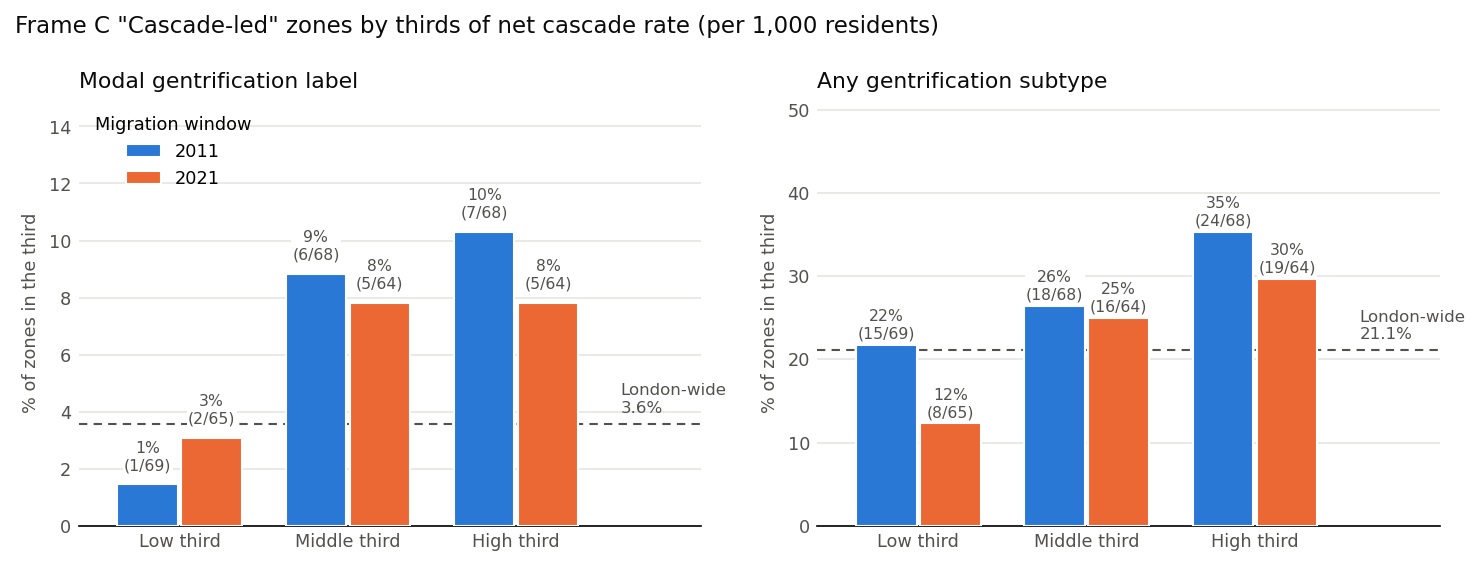

In [17]:
# Figure: label prevalence across thirds of net cascade rate, Frame C
C_2011, C_2021 = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), dpi=150, sharey=False)
for ax, (col, title, bench) in zip(axes, [
        ("Modal label %", "Modal gentrification label", london_modal),
        ("Any gentrification %", "Any gentrification subtype", london_any)]):
    x = np.arange(3)
    w = 0.36
    for i, (Y, colr) in enumerate([("2011", C_2011), ("2021", C_2021)]):
        t = a2_thirds[("C", Y)].iloc[:3]
        vals = t[col].values
        bars = ax.bar(x + (i - 0.5) * (w + 0.02), vals, width=w, color=colr,
                      edgecolor="white", linewidth=1, label=Y, zorder=3)
        for b, v, n, k in zip(bars, vals, t["Zones"], t[col.replace(" %", "")]):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.4, f"{v:.0f}%\n({k}/{n})",
                    ha="center", va="bottom", fontsize=7.5, color=MUTED, zorder=5,
                    bbox=dict(facecolor="white", edgecolor="none", pad=0.6))
    ax.axhline(bench, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=2)
    ax.set_xticks(x, ["Low third", "Middle third", "High third"])
    ax.set_title(title, loc="left", fontsize=10.5, color=INK)
    ax.set_xlim(-0.6, 3.1)
    top = max(a2_thirds[("C", Y)].iloc[:3][col].max() for Y in ["2011", "2021"])
    ax.set_ylim(0, max(top * 1.45, bench * 1.6))
    ax.text(2.62, bench + ax.get_ylim()[1] * 0.02, f"London-wide\n{bench:.1f}%",
            va="bottom", ha="left", fontsize=8, color=MUTED)
    ax.yaxis.grid(True, color=GRID, lw=0.8, zorder=0)
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
    ax.set_ylabel("% of zones in the third", fontsize=8.5, color=MUTED)
axes[0].legend(frameon=False, fontsize=8.5, loc="upper left", title="Migration window",
               title_fontsize=8.5)
fig.suptitle("Frame C \"Cascade-led\" zones by thirds of net cascade rate (per 1,000 residents)",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(OUT_FIG_THIRDS, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 5. Rates by mechanism profile, Frame C (A3)

Median moves per 1,000 residents for each Frame C mechanism profile, the whole "Cascade-led" regime and all London zones. The first five columns are candidates for Table 5. Departures to more deprived areas are split into those within London and those to the rest of England, matching the profile definitions.

In [18]:
rate_cols = [("IW_rate", "Arrivals from less deprived"),
             ("OP_int_rate", "Departures to more deprived, within London"),
             ("OP_ext_rate", "Departures to more deprived, rest of England"),
             ("xdec_rate_C", "Hierarchy-crossing rate"),
             ("net_rate_C", "Net cascade rate"),
             ("OW_rate", "Departures to less deprived"),
             ("IP_rate", "Arrivals from more deprived")]

rows = []
for yr, Y in YEARS:
    groups = [(name, d[f"leaf_{yr}"].eq(key)) for key, name in PROFILES]
    groups += [("All Cascade-led", d[f"Typ_C_{yr}"].eq("Cascade-led")),
               ("All London zones", pd.Series(True, index=d.index))]
    for name, m in groups:
        row = {"Window": Y, "Group": name, "Zones": int(m.sum())}
        for c, lab in rate_cols:
            row[lab] = d.loc[m, f"{c}_{Y}"].median()
        rows.append(row)
a3 = pd.DataFrame(rows).set_index(["Window", "Group"])
print("Median moves per 1,000 usual residents, Frame C")
display(a3.style.format({lab: "{:.1f}" for _, lab in rate_cols}))

Median moves per 1,000 usual residents, Frame C


## 6. Camden 026 and Croydon 044 (Figure 4)

Counts and rates for the two Figure 4 zones. "ext" gives moves to or from the rest of England, as in the Figure 4 labels. The last rows compare the two zones: how many times larger Camden 026's flows are than Croydon 044's, in counts and per resident.

In [19]:
case_rows = []
for code_, name in CASES:
    r = d.loc[d.msoa11cd.eq(code_)].iloc[0]
    for yr, Y in YEARS:
        P = r[f"pop_{Y}"]
        row = {"Zone": name, "Window": Y, "Residents": int(round(P))}
        for k, lab in [("IW", "From wealthier"), ("OP", "To poorer"),
                       ("OW", "To wealthier"), ("IP", "From poorer")]:
            n, x = int(r[f"{k}_{Y}"]), int(r[f"{k}_ext_{Y}"])
            row[f"{lab}: count (ext)"] = f"{n:,} ({x:,})" if x else f"{n:,}"
            row[f"{lab}: per 1,000"] = PER * n / P
        row["Hierarchy-crossing: count"] = int(r[f"xdec_C_{Y}"])
        row["Hierarchy-crossing: per 1,000"] = r[f"xdec_rate_C_{Y}"]
        row["Net cascade: count"] = int(r[f"net_C_{Y}"])
        row["Net cascade: per 1,000"] = r[f"net_rate_C_{Y}"]
        row["Regime (Frame C)"] = r[f"Typ_C_{yr}"]
        case_rows.append(row)
cases = pd.DataFrame(case_rows).set_index(["Zone", "Window"])
display(cases.T.style.format(lambda v: f"{v:,.1f}" if isinstance(v, float) else v))

ratio = []
for Y in ["2011", "2021"]:
    cam, cro = cases.loc[("Camden 026", Y)], cases.loc[("Croydon 044", Y)]
    ratio.append({"Window": Y,
                  "Residents, Camden ÷ Croydon": cam["Residents"] / cro["Residents"],
                  "Hierarchy-crossing moves, counts": cam["Hierarchy-crossing: count"] / cro["Hierarchy-crossing: count"],
                  "Hierarchy-crossing moves, per 1,000": cam["Hierarchy-crossing: per 1,000"] / cro["Hierarchy-crossing: per 1,000"]})
print("Camden 026 relative to Croydon 044 (times)")
display(pd.DataFrame(ratio).set_index("Window").style.format("{:.2f}"))

Camden 026 relative to Croydon 044 (times)


,"Residents, Camden ÷ Croydon","Hierarchy-crossing moves, counts","Hierarchy-crossing moves, per 1,000"
Window,,,
2011,1.00,5.03,5.02
2021,0.70,3.74,5.32


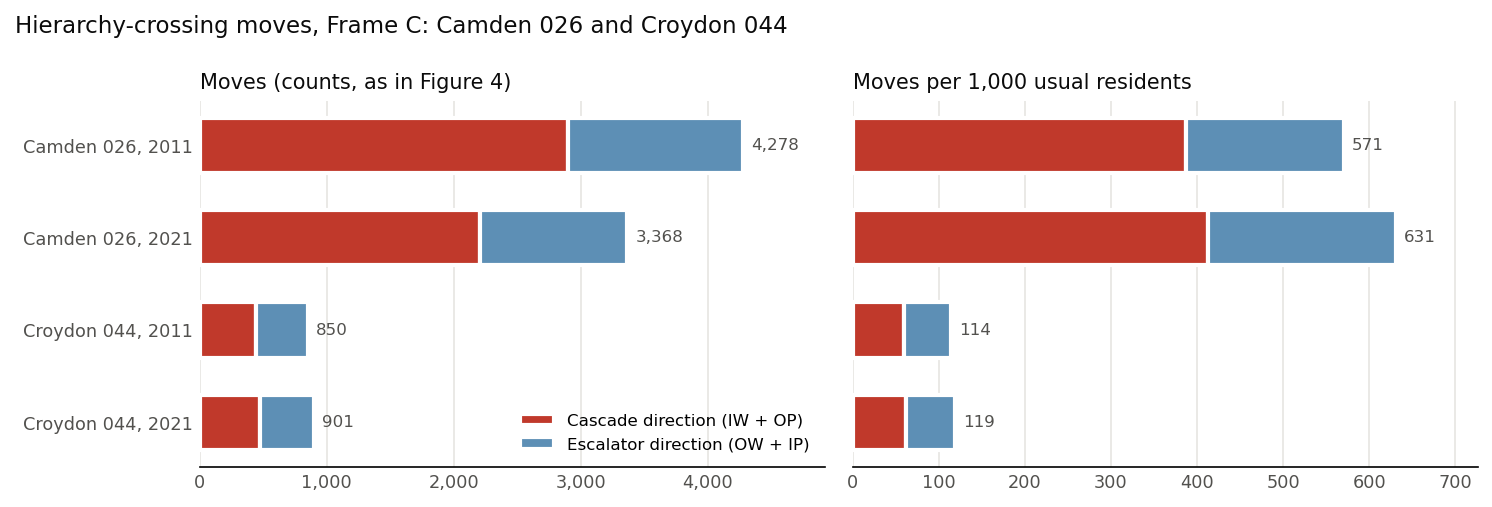

In [20]:
# Figure: the two zones in counts and per 1,000 residents, Frame C
# Colours follow Figure 4 (flow_yee_palette_v2.ALLUVIAL): cascade red, escalator blue.
try:
    from flow_yee_palette_v2 import ALLUVIAL
    C_CASC, C_ESC = ALLUVIAL["cascade_in"], ALLUVIAL["counter_in"]
except Exception:
    C_CASC, C_ESC = "#c0392b", "#5d8fb5"

labels, casc_n, esc_n, casc_r, esc_r = [], [], [], [], []
for code_, name in CASES:
    r = d.loc[d.msoa11cd.eq(code_)].iloc[0]
    for yr, Y in YEARS:
        P = r[f"pop_{Y}"]
        c = r[f"IW_{Y}"] + r[f"OP_{Y}"]
        e = r[f"OW_{Y}"] + r[f"IP_{Y}"]
        labels.append(f"{name}, {Y}")
        casc_n.append(c); esc_n.append(e)
        casc_r.append(PER * c / P); esc_r.append(PER * e / P)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), dpi=150, sharey=True)
ypos = np.arange(len(labels))[::-1]
for ax, cn, en, title, unit in [
        (axes[0], casc_n, esc_n, "Moves (counts, as in Figure 4)", "{:,.0f}"),
        (axes[1], casc_r, esc_r, "Moves per 1,000 usual residents", "{:,.0f}")]:
    ax.barh(ypos, cn, height=0.6, color=C_CASC, edgecolor="white", linewidth=2,
            label="Cascade direction (IW + OP)", zorder=3)
    ax.barh(ypos, en, left=cn, height=0.6, color=C_ESC, edgecolor="white", linewidth=2,
            label="Escalator direction (OW + IP)", zorder=3)
    tot = np.array(cn) + np.array(en)
    for yv, t in zip(ypos, tot):
        ax.text(t + tot.max() * 0.015, yv, unit.format(t), va="center", fontsize=8, color=MUTED)
    ax.set_xlim(0, tot.max() * 1.15)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.set_title(title, loc="left", fontsize=10, color=INK)
    ax.xaxis.grid(True, color=GRID, lw=0.8, zorder=0)
    for s in ["top", "right", "left"]:
        ax.spines[s].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=8.5, length=0)
axes[0].set_yticks(ypos, labels)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Hierarchy-crossing moves, Frame C: Camden 026 and Croydon 044",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(OUT_FIG_CASES, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 7. Summary and saved outputs

The cell below prints the key numbers from this run. They are computed, not typed, so they stay correct if the inputs change, for example once the exact 2021 lookup is added.

In [21]:
def pct(x):
    return f"{x:.1f}%"

print(f"Population source for 2021 geography: {geo_source}"
      + (f" ({len(approx_2021)} zones apportioned)" if approx_2021 else ""))
print()
for Y in ["2011", "2021"]:
    cl = d[f"Typ_C_{Y[2:]}"].eq("Cascade-led")
    print(f"{Y}, Frame C: hierarchy-crossing moves median "
          f"{d[f'xdec_rate_C_{Y}'].median():.0f} per 1,000 residents across all zones; "
          f"net cascade rate median {d.loc[cl, f'net_rate_C_{Y}'].median():.1f} per 1,000 "
          f"in the {int(cl.sum())} Cascade-led zones.")
print()
print("A1. Spearman's ρ with IMD percentile change, rates vs the published measures (all frames/windows):")
print(f"    Cascade_Dominance {a1['Cascade_Dominance'].min():.3f} to {a1['Cascade_Dominance'].max():.3f}; "
      f"net cascade rate {a1['Net cascade rate'].min():.3f} to {a1['Net cascade rate'].max():.3f}; "
      f"hierarchy-crossing rate {a1['Hierarchy-crossing rate'].min():.3f} to {a1['Hierarchy-crossing rate'].max():.3f}.")
print(f"    Retained-moves rate alone: {a1b['Retained-moves rate vs IMD change'].min():.3f} to "
      f"{a1b['Retained-moves rate vs IMD change'].max():.3f}; hierarchy-crossing rate within inner or outer "
      f"London: {a1b.filter(like='within').min().min():.3f} to {a1b.filter(like='within').max().max():.3f}.")
print()
print("A2. Frame C, Cascade-led zones by thirds of net cascade rate (low / middle / high):")
for Y in ["2011", "2021"]:
    t = a2_thirds[("C", Y)].iloc[:3]
    print(f"    {Y}: modal label " + " / ".join(pct(v) for v in t["Modal label %"])
          + f" (London {london_modal:.1f}%); any gentrification "
          + " / ".join(pct(v) for v in t["Any gentrification %"]) + f" (London {london_any:.1f}%)")
t4c = a2_t4[a2_t4.Frame.eq("C")]
for Y in ["2011", "2021"]:
    s = t4c[t4c.Window.eq(Y)].set_index("Cascade-led zones kept")["Cramér's V"]
    print(f"    {Y}: Cramér's V, all Cascade-led {s.iloc[0]:.3f} -> middle+high {s.iloc[1]:.3f} "
          f"-> high third only {s.iloc[2]:.3f}")
print()
for Y in ["2011", "2021"]:
    r = pd.DataFrame(ratio).set_index("Window").loc[Y]
    print(f"Figure 4, {Y}: Camden 026 has {r.iloc[1]:.1f}x Croydon 044's hierarchy-crossing moves "
          f"in counts and {r.iloc[2]:.1f}x per resident.")

Population source for 2021 geography: ONS MSOA 2011-2021 lookup via geo_harmonise.build_harmonisation (exact)

2011, Frame C: hierarchy-crossing moves median 180 per 1,000 residents across all zones; net cascade rate median 16.1 per 1,000 in the 205 Cascade-led zones.
2021, Frame C: hierarchy-crossing moves median 168 per 1,000 residents across all zones; net cascade rate median 18.2 per 1,000 in the 193 Cascade-led zones.

A1. Spearman's ρ with IMD percentile change, rates vs the published measures (all frames/windows):
    Cascade_Dominance 0.053 to 0.173; net cascade rate -0.032 to 0.160; hierarchy-crossing rate 0.336 to 0.382.
    Retained-moves rate alone: 0.423 to 0.436; hierarchy-crossing rate within inner or outer London: -0.003 to 0.200.

A2. Frame C, Cascade-led zones by thirds of net cascade rate (low / middle / high):
    2011: modal label 1.4% / 8.8% / 10.3% (London 3.6%); any gentrification 21.7% / 26.5% / 35.3% (London 21.1%)
    2021: modal label 3.1% / 7.8% / 7.8% (Lon

In [22]:
# zone-level file: populations and every rate used above
zone_cols = (["msoa11cd", "msoa_name", "ladnm", "Ring", "pop_2011", "pop_2021", "pop21_approx"]
             + [f"{m}_{fr}_{Y}" for m in ("retained_rate", "xdec_rate", "net_rate")
                for fr in FRAMES for _, Y in YEARS]
             + [f"{k}{s}_rate_{Y}" for k in ("IW", "OP", "OW", "IP") for s in ("", "_int", "_ext")
                for _, Y in YEARS])
d[zone_cols].to_csv(OUT_ZONES, index=False, float_format="%.4f")

# long results file: every table above
res = []
for (fr, Y), t in a2_thirds.items():
    res.append(t.assign(table="A2 thirds", Frame=fr, Window=Y))
res.append(a2_t4.assign(table="A2 Table 4 kept"))
res.append(pd.DataFrame(a2_rho).assign(table="A2 rho within Cascade-led"))
res.append(a1.reset_index().assign(table="A1 Spearman, all zones"))
res.append(a1b.reset_index().assign(table="A1 hierarchy-crossing rate decomposition"))
res.append(a3.reset_index().assign(table="A3 profile medians, Frame C"))
res.append(cases.reset_index().assign(table="Cases Camden 026 and Croydon 044"))
pd.concat(res, ignore_index=True).to_csv(OUT_RESULTS, index=False)
for p in [OUT_ZONES, OUT_RESULTS, OUT_FIG_THIRDS, OUT_FIG_CASES]:
    print("wrote", p.relative_to(ROOT))

wrote outputs/diag_population_rates_zones_20261112.csv
wrote outputs/diag_population_rates_results_20261112.csv
wrote outputs/diag_population_rates_thirds_20261112.png
wrote outputs/diag_population_rates_cases_20261112.png


### Caveats for the write-up

- **Denominator.** Census usual residents on census day, at the end of each one-year window. They include that year's arrivals and exclude its leavers. This is the standard approximation for census migration rates and does not affect the comparisons between zones.
- **Retained moves only.** Moves within a zone, involving Wales, or from Scotland, Northern Ireland or overseas are excluded (Section 3.1), so the rates understate total turnover.
- **2021.** The window and the census population both fall in the COVID-19 pandemic. Students were counted at their term-time address even if they were not living there, which may affect inner-London denominators.
- **Disclosure control.** Record swapping (2011) and cell-key perturbation (2021) affect both flows and populations slightly.
- **Small counts in A2.** At most 14 "Cascade-led" zones carry the modal label in any frame and window, so thirds contain only a handful of labelled zones.